In [1]:
# Block 1
%load_ext autoreload
%autoreload 1

# Watch the modules these cells call into
%aimport utility
%aimport config
%aimport yolo_detector

import numpy as np
import pandas as pd

import torch

import config
import utility

from yolo_detector import YOLODetector

In [2]:
# Block 2
LESION_TYPE = "mass"
# LESION_TYPE = "calc"

# Seed python, numpy and torch, and pin the cuDNN algorithm
utility.set_deterministic()

config.YOLO_WORKSPACE.mkdir(parents=True, exist_ok=True)
config.MODELS_ROOT.mkdir(parents=True, exist_ok=True)

device = 0 if torch.cuda.is_available() else "cpu"

print(f"Device       : {device}")
print(f"Lesion type  : {LESION_TYPE}")
print(f"Frame        : long side {config.YOLO_IMAGE_SIZE} px")
print(f"Classes      : {config.CLASS_NAMES}")
print(f"Folds        : {config.OOF_FOLDS}")
print(f"Workspace    : {config.YOLO_WORKSPACE}")
print(f"Models       : {config.MODELS_ROOT}")

Device       : 0
Lesion type  : mass
Frame        : long side 768 px
Classes      : ('benign', 'malignant')
Folds        : (0, 1, 2, 3, 4)
Workspace    : C:\Users\User\Desktop\sch work\fyp\03_yolo_workspace
Models       : C:\Users\User\Desktop\sch work\fyp\models


In [3]:
# Block 3
# Load metadata
metadata = pd.read_csv(config.PROJECT_ROOT / f"{LESION_TYPE}_metadata.csv")

display(metadata.head())

print(f"Rows               : {len(metadata):,}")
print(f"Unique mammograms  : {metadata['full_image'].nunique():,}")
print(f"Unique lesions     : {metadata['mask_image'].nunique():,}")

,patient_id,breast density,left or right breast,image view,abnormality id,abnormality type,mass shape,mass margins,assessment,pathology,...,split,fold,full_image,crop_image,mask_image,breast_mask,breast_xmin,breast_ymin,breast_xmax,breast_ymax
0,P_00016,4,LEFT,CC,1,mass,IRREGULAR,SPICULATED,5,MALIGNANT,...,test,-1,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,198,0,471,1023
1,P_00016,4,LEFT,MLO,1,mass,IRREGULAR,SPICULATED,5,MALIGNANT,...,test,-1,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,0,0,374,1023
2,P_00017,2,LEFT,CC,1,mass,ROUND,CIRCUMSCRIBED,4,MALIGNANT,...,trainval,0,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,0,0,554,1023
3,P_00017,2,LEFT,MLO,1,mass,ROUND,ILL_DEFINED,4,MALIGNANT,...,trainval,0,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,0,0,576,1023
4,P_00032,3,RIGHT,CC,1,mass,ROUND,OBSCURED,0,BENIGN,...,trainval,2,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,153,0,528,1023


Rows               : 1,696
Unique mammograms  : 1,592
Unique lesions     : 1,696


In [4]:
# Block 4
# Per-mammogram split, then the fold 0 validation set
groups = utility.group_mammograms(metadata)

# Out-of-fold predictions cover the trainval split only; test stays held out
trainval_df = groups[groups["split"] == "trainval"].reset_index(drop=True)
test_df = groups[groups["split"] == "test"].reset_index(drop=True)

train_df, val_df = utility.oof_split(trainval_df, config.VAL_FOLD)

print(f"Trainval: {len(trainval_df):,} mammograms, folds {trainval_df['fold'].value_counts().sort_index().to_dict()}")
print(f"Test    : {len(test_df):,} mammograms, held out")
print(f"Fold {config.VAL_FOLD}: train {len(train_df):,}, val {len(val_df):,}")

Trainval: 1,272 mammograms, folds {0: 264, 1: 248, 2: 248, 3: 253, 4: 259}
Test    : 320 mammograms, held out
Fold 0: train 1,008, val 264


In [5]:
# Block 5
# Prepare one sample through the YOLO pipeline
yolo = YOLODetector(lesion_type=LESION_TYPE, device=device)

image, boxes, class_labels = yolo.prepare(trainval_df.iloc[0])

counts = np.bincount(class_labels, minlength=config.CLASS_COUNT)

print(f"Frame     : {image.shape}")
print(f"GT boxes  : {len(boxes)}")
print(f"Classes   : " + ", ".join(f"{name} {count}" for name, count in zip(config.CLASS_NAMES, counts)))
print(f"Box bounds: {boxes.min(axis=0).round(1).tolist()} to {boxes.max(axis=0).round(1).tolist()}")
print(f"Export    : {yolo.root}")

Frame     : (768, 416)
GT boxes  : 1
Classes   : benign 0, malignant 1
Box bounds: [33.0, 490.5, 52.5, 512.2000122070312] to [33.0, 490.5, 52.5, 512.2000122070312]
Export    : C:\Users\User\Desktop\sch work\fyp\03_yolo_workspace\mass


In [6]:
# Block 6
# Ultralytics trains from PNGs and label files, so the dataset is what the export writes
split_counts = yolo.export_fold(trainval_df, config.VAL_FOLD)

for split, (image_count, label_count) in split_counts.items():
    print(f"{split:5s} images {image_count:4d}  labels {label_count:4d}")

train images 1008  labels 1008
val   images  264  labels  264


In [7]:
# Block 7
# Ultralytics builds the model from the dataset description, so this is the build step
yaml_path = yolo.write_data_yaml()

print(f"Data yaml : {yaml_path}")
print(f"Model     : {config.YOLO_MODEL}")
print(
    f"Schedule  : {config.YOLO_EPOCHS} epochs, batch {config.YOLO_BATCH_SIZE}, "
    f"imgsz {config.YOLO_IMAGE_SIZE}, patience {config.YOLO_PATIENCE}"
)

Data yaml : C:\Users\User\Desktop\sch work\fyp\03_yolo_workspace\mass\data.yaml
Model     : yolo26s.pt
Schedule  : 50 epochs, batch 12, imgsz 768, patience 15


In [8]:
# Block 8
# One model per fold; a completed fold is skipped, so re-running resumes the rest
print("Loss     : ultralytics box/cls/regression terms, summed")
print(
    f"Schedule : {config.YOLO_OPTIMIZER} lr {config.YOLO_LR}, cosine over {config.YOLO_EPOCHS} epochs, "
    f"patience {config.YOLO_PATIENCE}"
)
print(f"Export   : stacker floor {config.YOLO_STACKER_SCORE_THRESHOLD}, " f"top {config.YOLO_STACKER_TOP_K} per image")


oof_summary = {}

for fold in config.OOF_FOLDS:
    oof_summary[fold] = yolo.oof_fold(trainval_df, fold, LESION_TYPE, export=False)

# Export each fold's records and its ranked candidate feed for the stacker
exported = yolo.export_folds(trainval_df, LESION_TYPE)

pd.DataFrame.from_dict(exported, orient="index")

Loss     : ultralytics box/cls/regression terms, summed
Schedule : AdamW lr 0.002, cosine over 50 epochs, patience 15
Export   : stacker floor 0.05, top 100 per image
Fold 0: complete (val AP50 0.6303, 976 records), skipping
Epoch | box    | cls    | reg    | P      | R      | mAP50  | mAP50-95
1     | 2.2111 | 8.0618 | 0.0078 | 0.2042 | 0.1821 | 0.1246 | 0.0397
2     | 2.1488 | 2.9709 | 0.0078 | 0.2318 | 0.3506 | 0.1830 | 0.0739
3     | 2.0725 | 2.8630 | 0.0073 | 0.2768 | 0.4085 | 0.2284 | 0.0878
4     | 2.0568 | 2.7450 | 0.0072 | 0.3116 | 0.3940 | 0.2324 | 0.0896
5     | 2.1494 | 2.6805 | 0.0078 | 0.2769 | 0.2964 | 0.1800 | 0.0780
6     | 2.0736 | 2.7730 | 0.0075 | 0.3459 | 0.4375 | 0.2961 | 0.1128
7     | 1.9902 | 2.6113 | 0.0072 | 0.3225 | 0.3997 | 0.2502 | 0.0968
8     | 1.9597 | 2.6339 | 0.0068 | 0.3139 | 0.4387 | 0.2994 | 0.1157
9     | 2.0482 | 2.5200 | 0.0073 | 0.4058 | 0.4049 | 0.3294 | 0.1327
10    | 1.9593 | 2.5481 | 0.0069 | 0.3427 | 0.4115 | 0.3066 | 0.1197
11    | 1.9334

,fold,seed,epochs,best_epoch,best_val_ap50,record_count,image_count,fingerprint,candidate_count,exported
0,0,42,50,35,0.630340,976,264,fd10e1fc65da,11365,True
1,1,42,50,30,0.470396,1073,248,fd10e1fc65da,10987,True
2,2,42,50,31,0.549139,899,248,fd10e1fc65da,11390,True
3,3,42,50,47,0.535448,751,253,fd10e1fc65da,8563,True
4,4,42,50,40,0.582867,913,259,fd10e1fc65da,9989,True


In [9]:
# Block 9
# Coverage check: each fold's records stay inside their own fold and no test mammogram appears
fold_records_paths = {fold: config.fold_paths("yolo", LESION_TYPE, fold)["records"] for fold in config.OOF_FOLDS}

records_by_fold = utility.oof_records(fold_records_paths)
manifest = utility.read_oof_manifest(config.oof_manifest_path("yolo", LESION_TYPE))

print(f"Folds complete: {sorted(manifest['folds'])}")

trainval_ids = pd.Series([utility.mammogram_id(path) for path in trainval_df["full_image"]], index=trainval_df.index)
test_ids = {utility.mammogram_id(path) for path in test_df["full_image"]}

covered = []

for fold, frame in records_by_fold.items():
    fold_ids = set(frame["image_id"])
    expected_ids = set(trainval_ids[trainval_df["fold"] == fold])

    covered.extend(sorted(fold_ids))

    print(
        f"Fold {fold}: {frame['image_id'].nunique():,} mammograms, {len(frame):,} records, "
        f"outside its own fold: {len(fold_ids - expected_ids)}, "
        f"images with detections: {len(fold_ids)}/{len(expected_ids)}"
    )

print(f"OOF mammograms: {len(covered):,} rows, {len(set(covered)):,} unique of {len(trainval_df):,} trainval")
print(f"Test mammograms inside the OOF records: {len(set(covered) & test_ids)}")

Folds complete: ['0', '1', '2', '3', '4']
Fold 0: 256 mammograms, 976 records, outside its own fold: 0, images with detections: 256/264
Fold 1: 245 mammograms, 1,073 records, outside its own fold: 0, images with detections: 245/248
Fold 2: 241 mammograms, 899 records, outside its own fold: 0, images with detections: 241/248
Fold 3: 246 mammograms, 751 records, outside its own fold: 0, images with detections: 246/253
Fold 4: 256 mammograms, 913 records, outside its own fold: 0, images with detections: 256/259
OOF mammograms: 1,244 rows, 1,244 unique of 1,272 trainval
Test mammograms inside the OOF records: 0


In [10]:
# Block 10
# Fold manifest table
manifest_df = pd.DataFrame.from_dict(manifest["folds"], orient="index").sort_index()
manifest_df.index.name = "fold"

display(manifest_df)

,fold,seed,epochs,best_epoch,best_val_ap50,record_count,image_count,fingerprint,candidate_count,exported
fold,,,,,,,,,,
0,0,42,50,35,0.630340,976,264,fd10e1fc65da,11365,True
1,1,42,50,30,0.470396,1073,248,fd10e1fc65da,10987,True
2,2,42,50,31,0.549139,899,248,fd10e1fc65da,11390,True
3,3,42,50,47,0.535448,751,253,fd10e1fc65da,8563,True
4,4,42,50,40,0.582867,913,259,fd10e1fc65da,9989,True


infer:   0%|          | 0/264 [00:00<?, ?it/s]

Fold 0: 264 mammograms


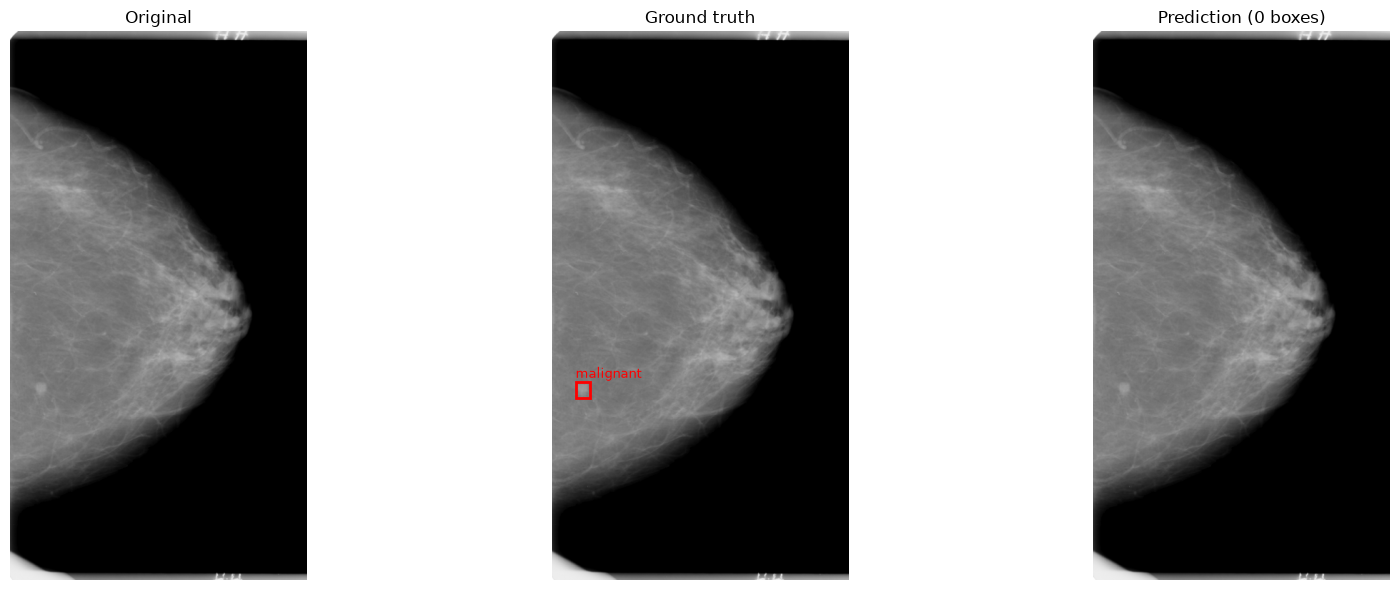

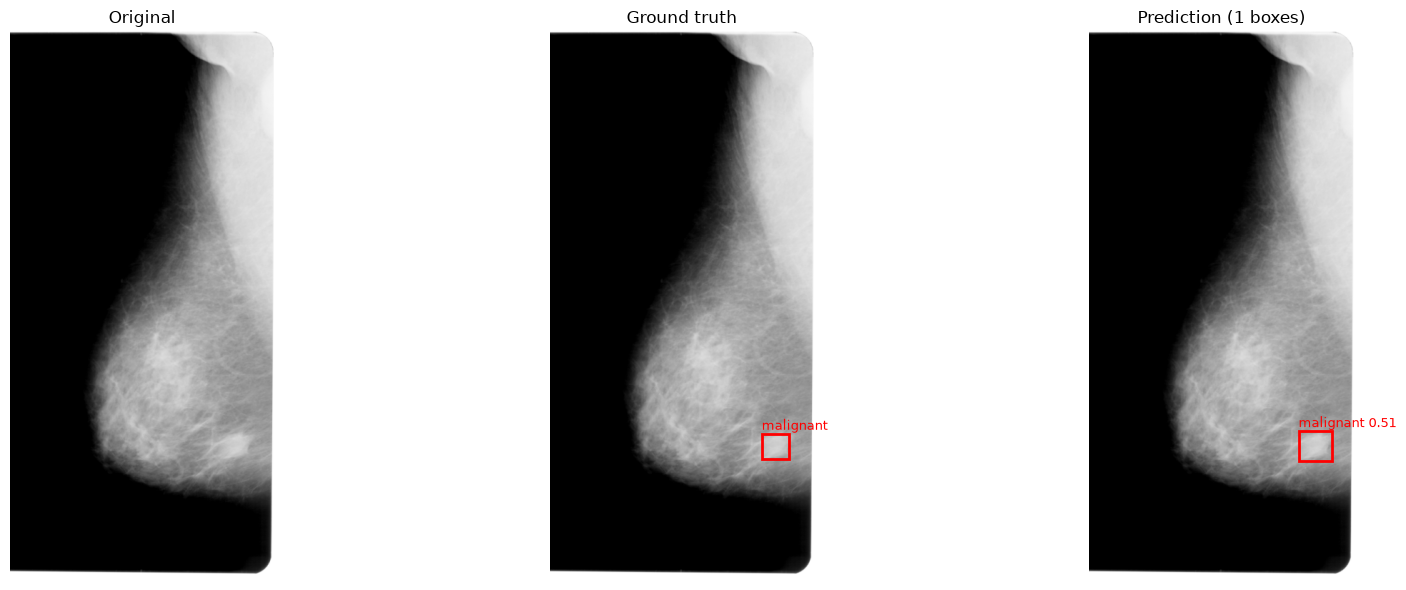

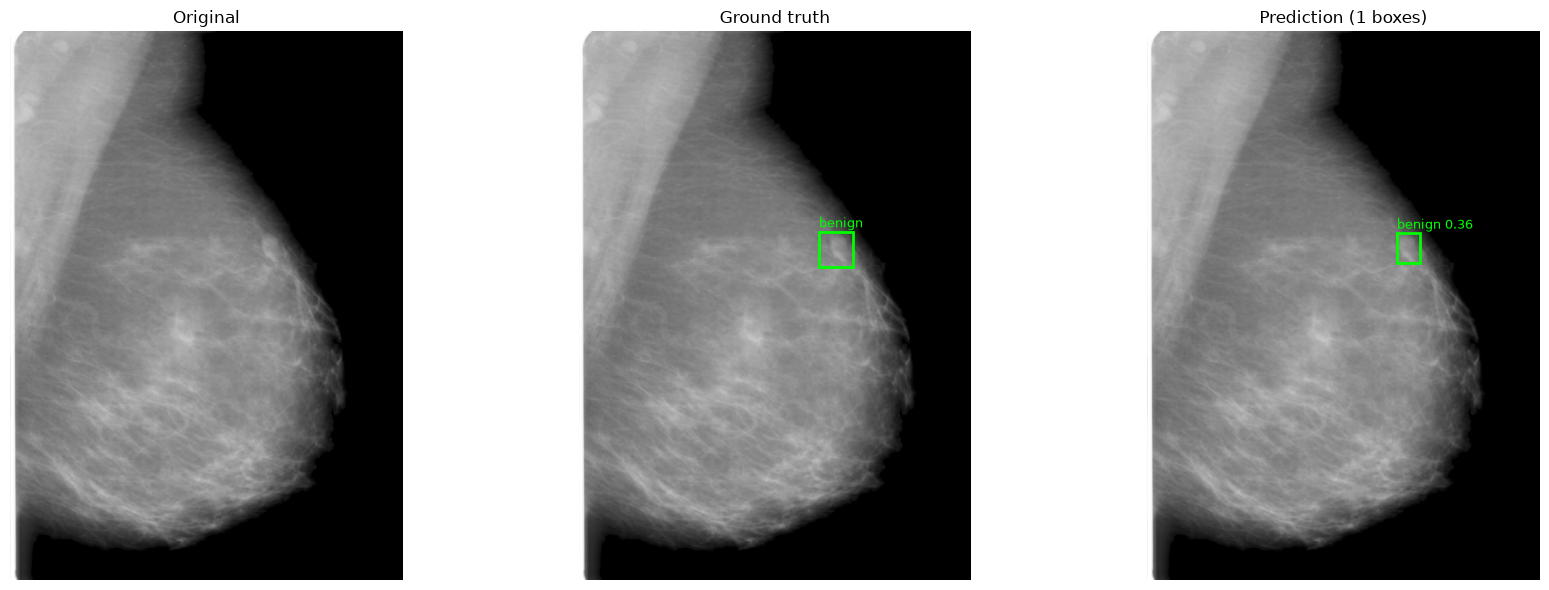

infer:   0%|          | 0/248 [00:00<?, ?it/s]

Fold 1: 248 mammograms


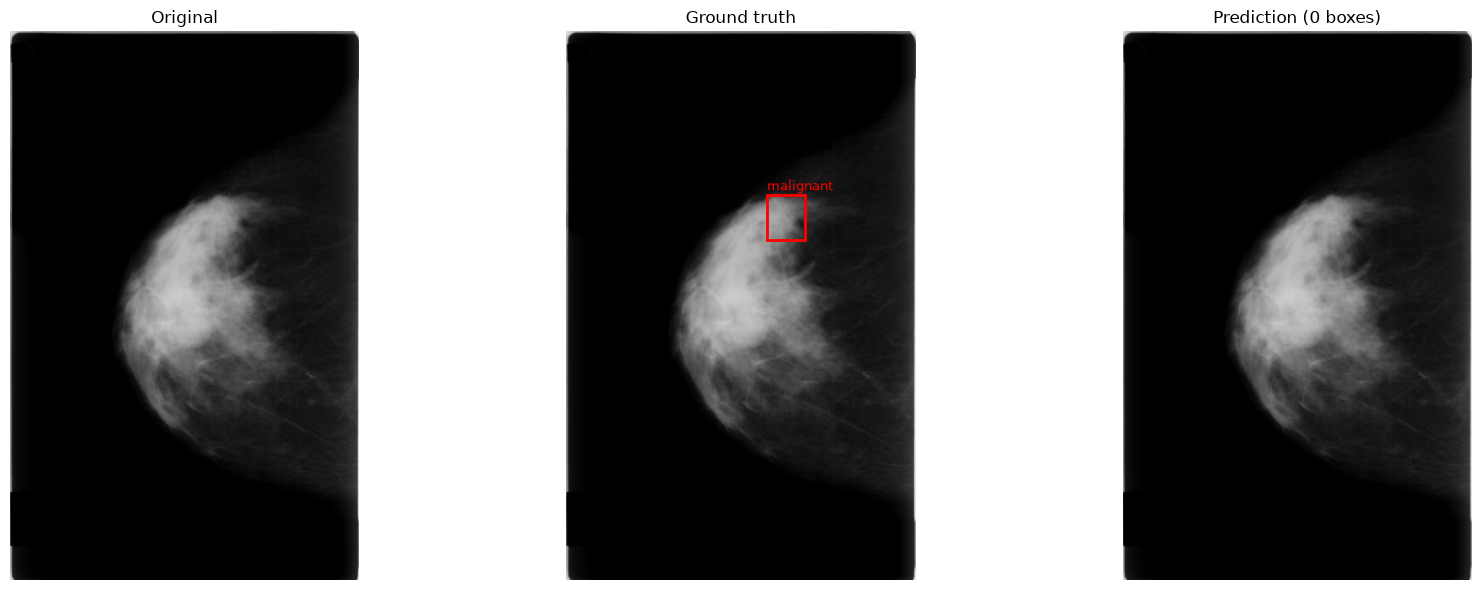

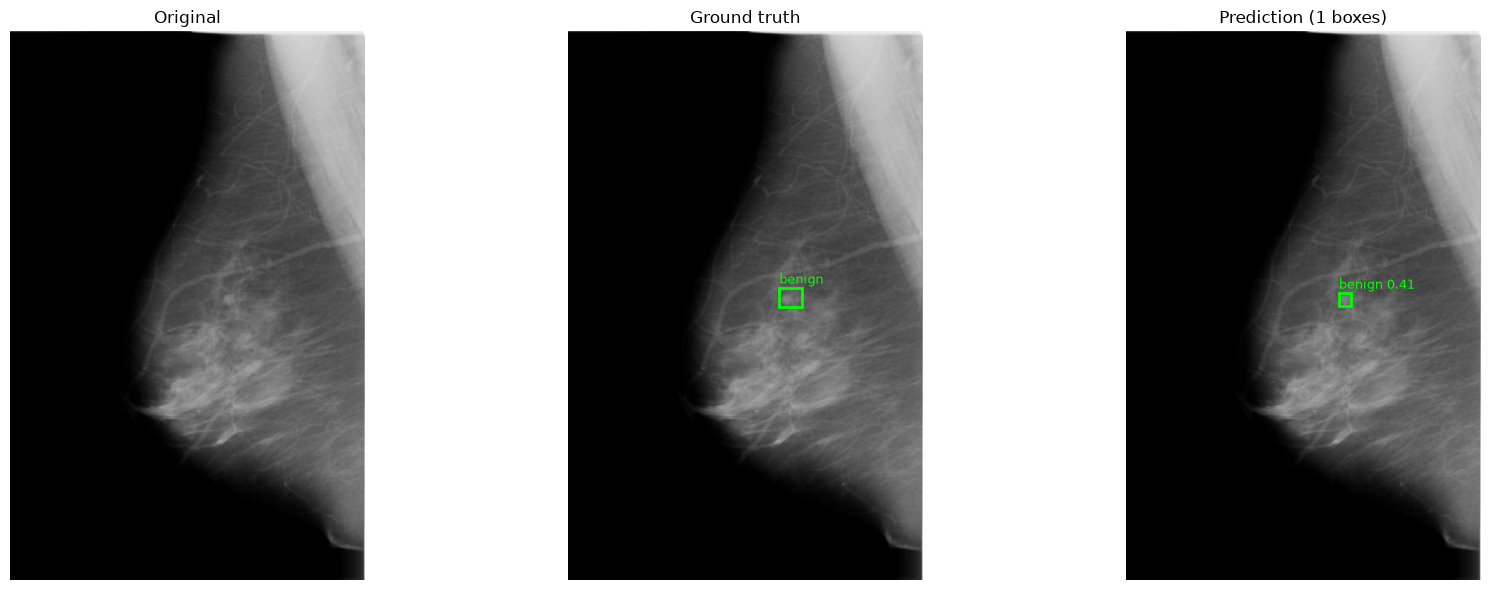

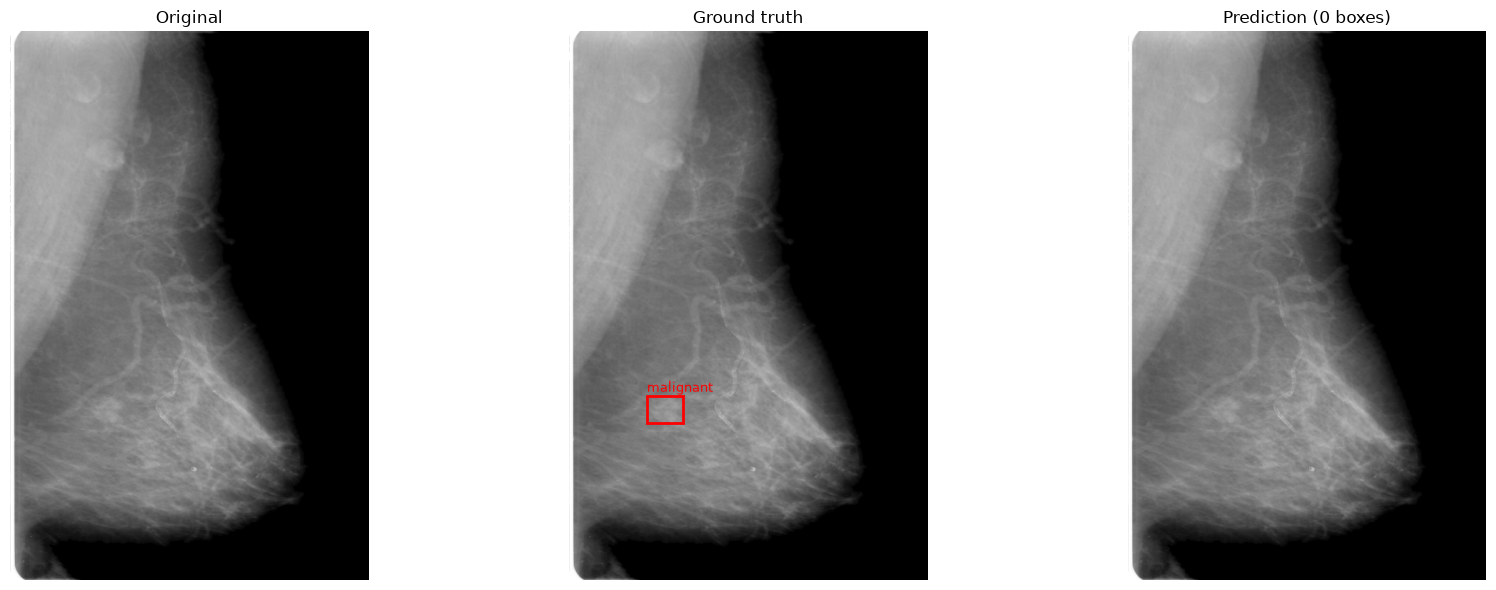

infer:   0%|          | 0/248 [00:00<?, ?it/s]

Fold 2: 248 mammograms


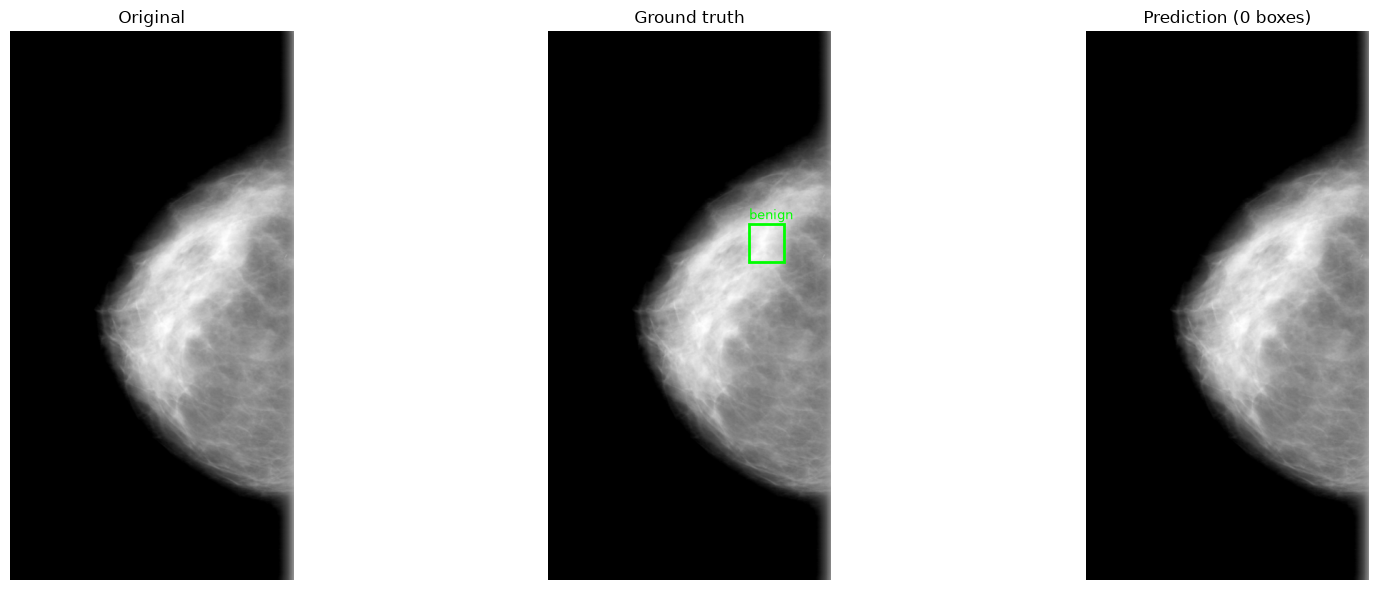

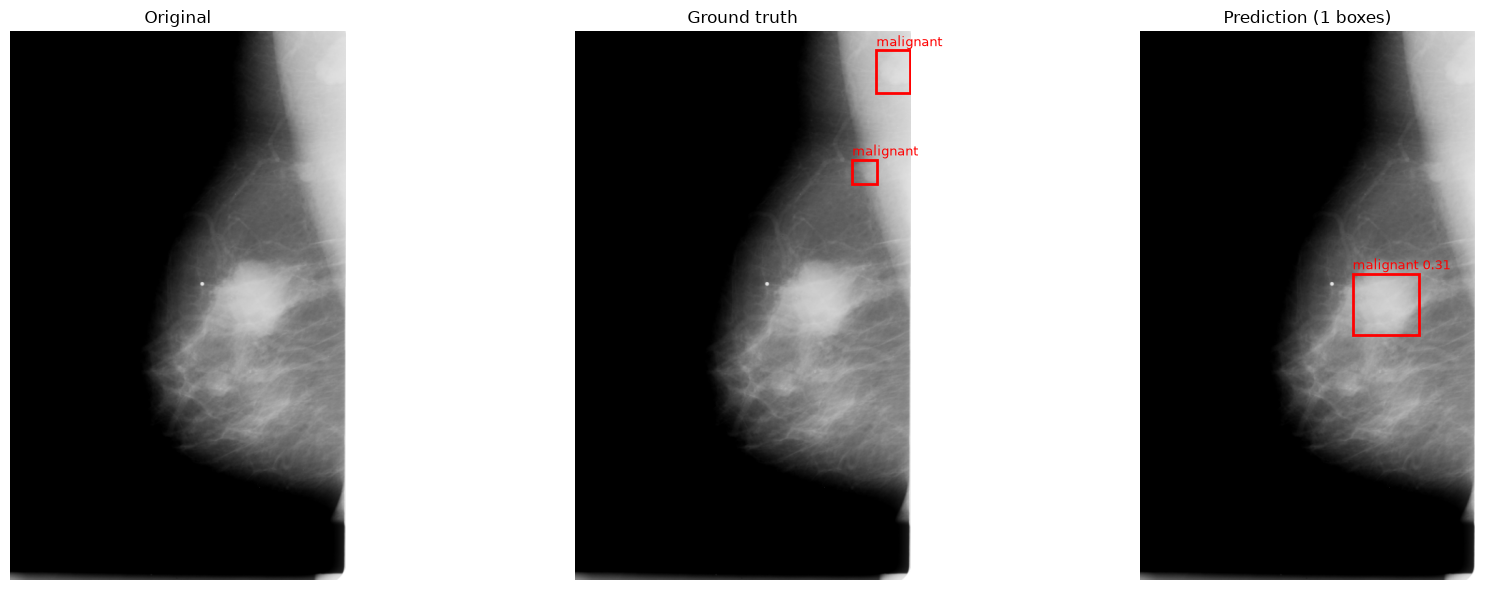

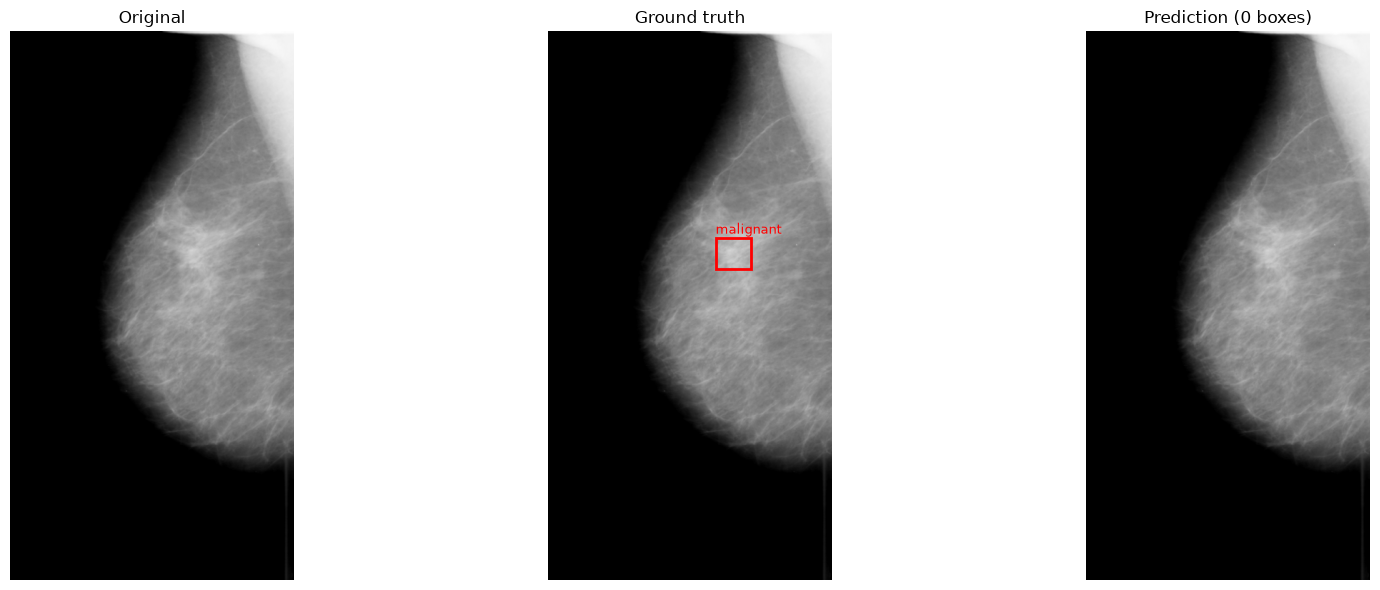

infer:   0%|          | 0/253 [00:00<?, ?it/s]

Fold 3: 253 mammograms


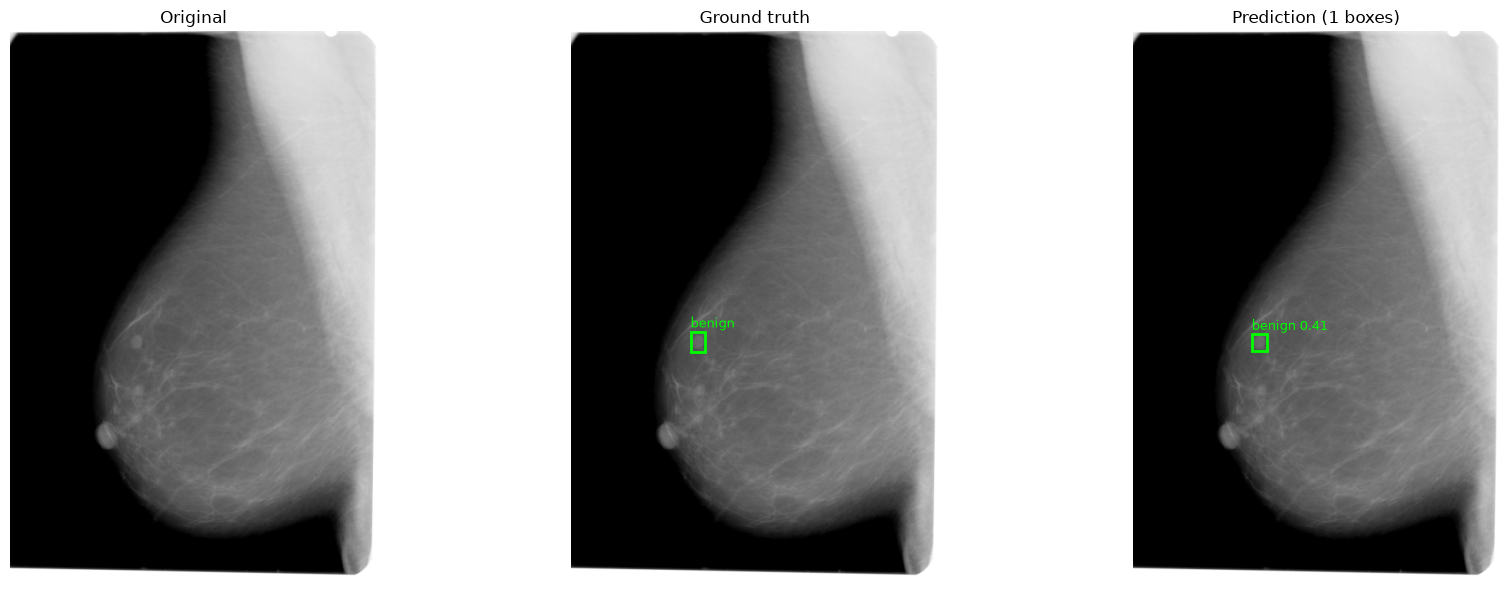

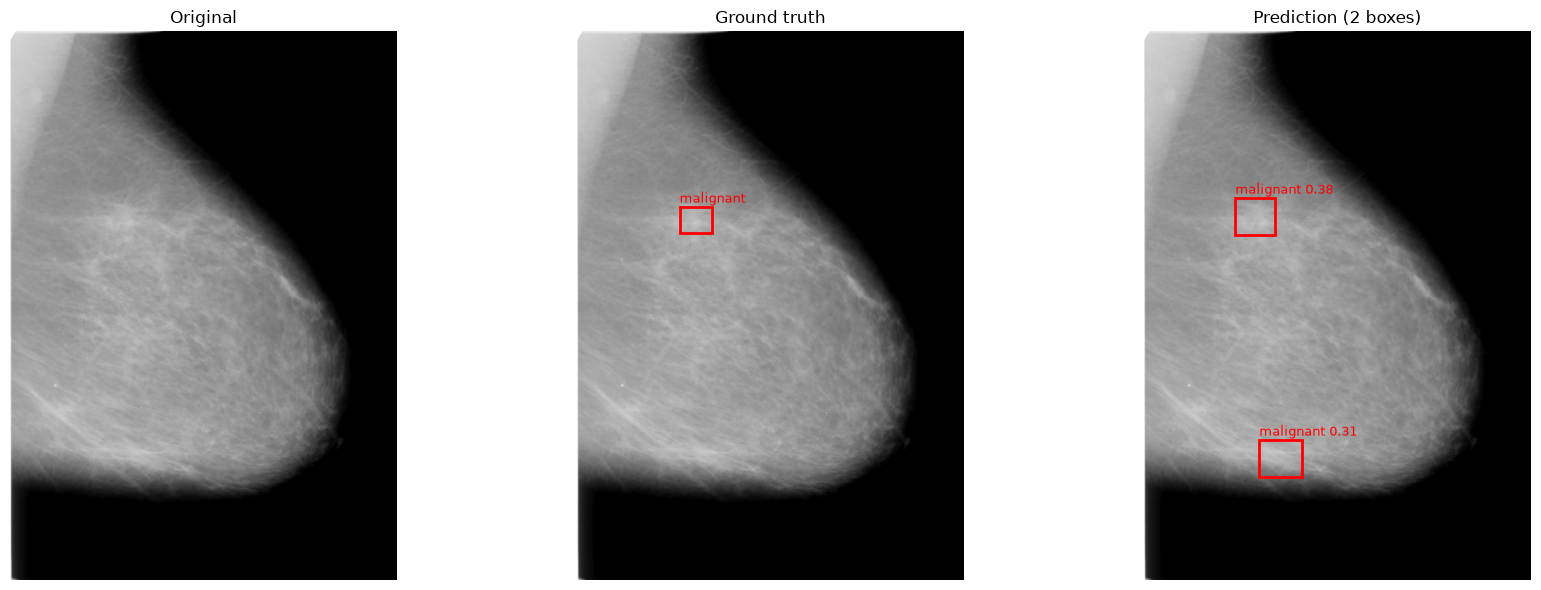

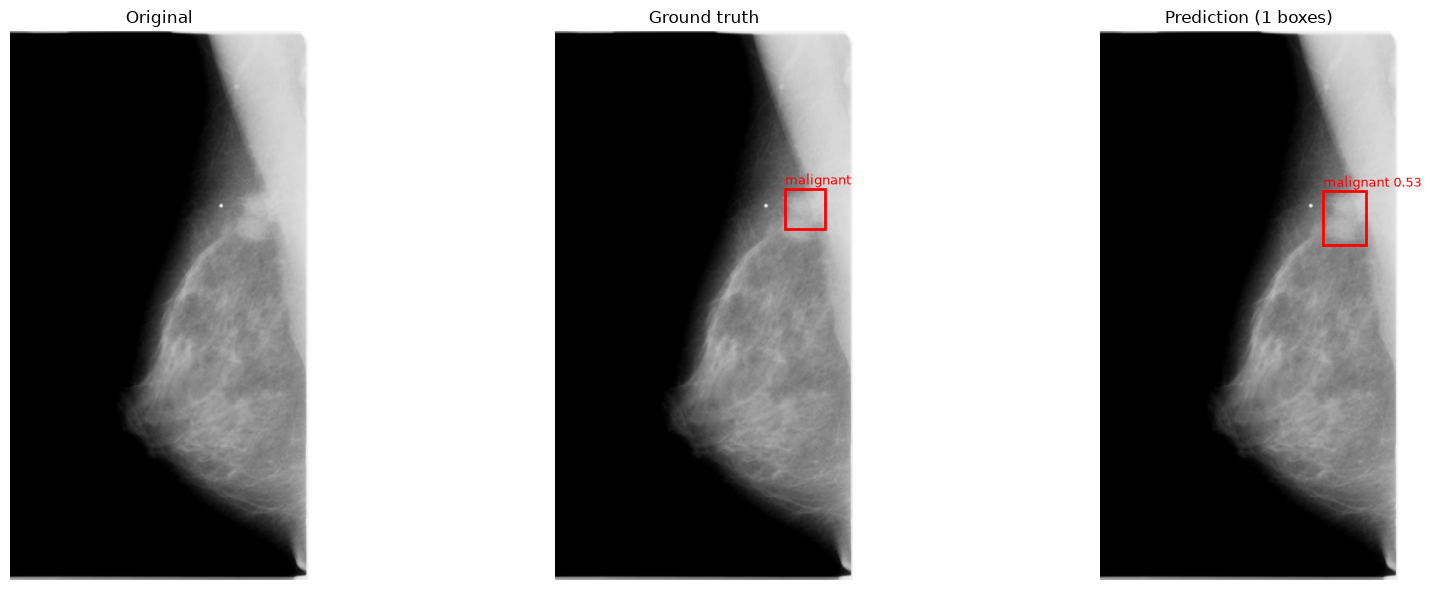

infer:   0%|          | 0/259 [00:00<?, ?it/s]

Fold 4: 259 mammograms


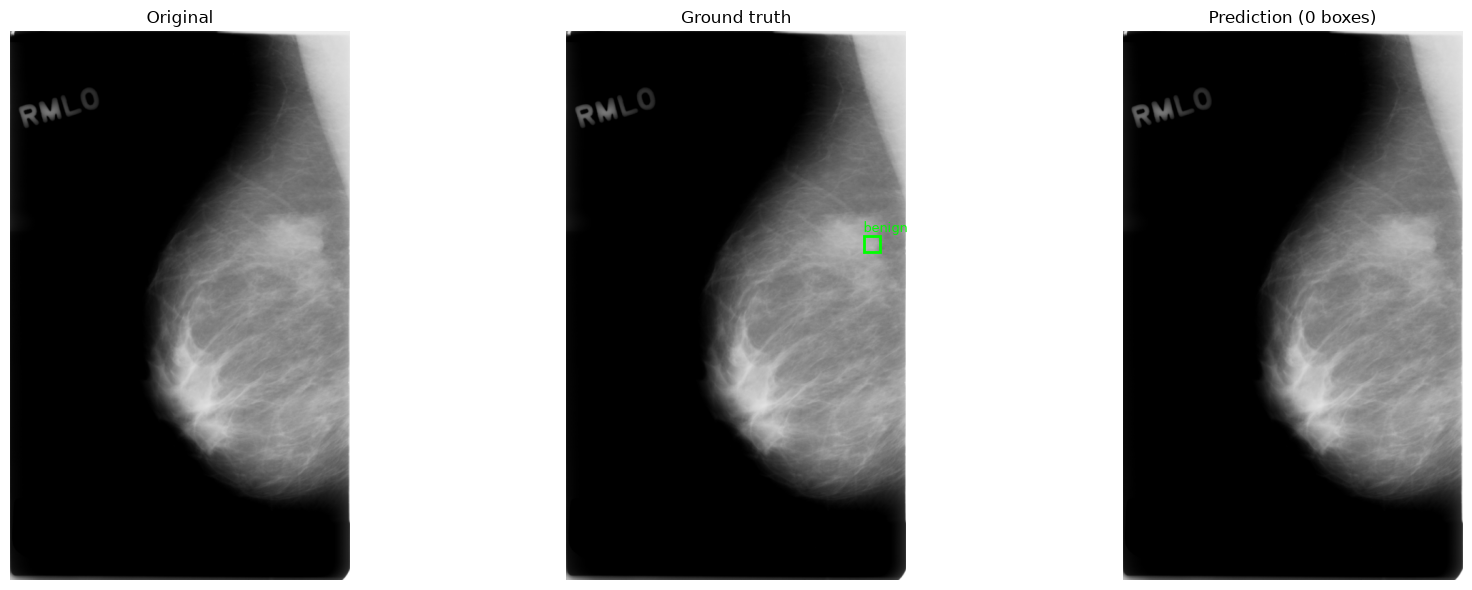

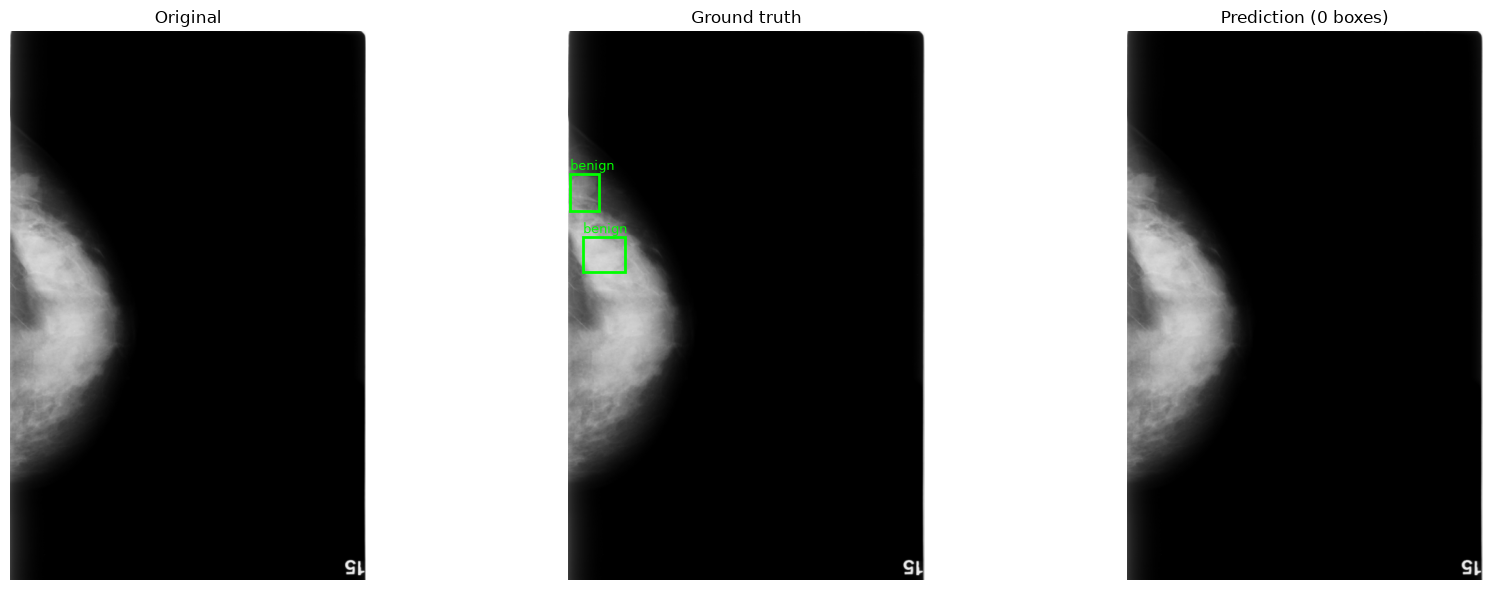

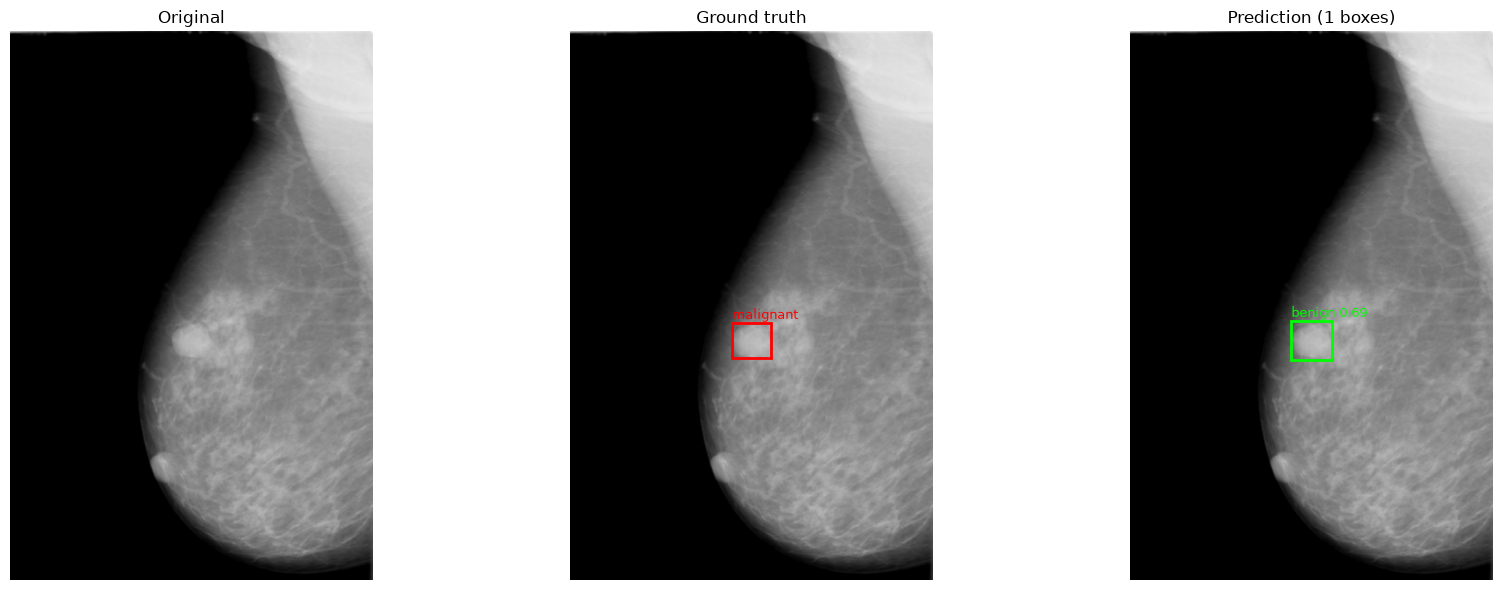

In [11]:
# Block 11
# Qualitative check: three held-out mammograms per fold at the operating threshold
fold_predictions = {}

for fold in config.OOF_FOLDS:
    scorer = YOLODetector(lesion_type=LESION_TYPE, device=device)
    scorer.load(config.fold_model_path("yolo", LESION_TYPE, fold))

    val_fold_df = trainval_df[trainval_df["fold"] == fold].reset_index(drop=True)
    fold_predictions[fold] = scorer.infer(val_fold_df)

    print(f"Fold {fold}: {len(val_fold_df):,} mammograms")

    for index in np.linspace(0, len(val_fold_df) - 1, 3, dtype=int):
        image, gt_boxes, gt_labels, boxes, scores, labels = scorer.predict_image(val_fold_df.iloc[index])

        utility.visualize_detections(image, gt_boxes, gt_labels, boxes, scores, labels, config.CLASS_NAMES)

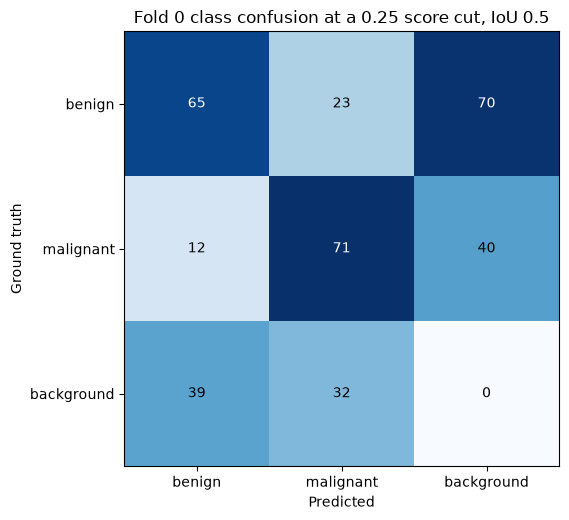

Fold 0
True positives  : 136
False negatives : 110
False positives : 71
Misclassified   : 35


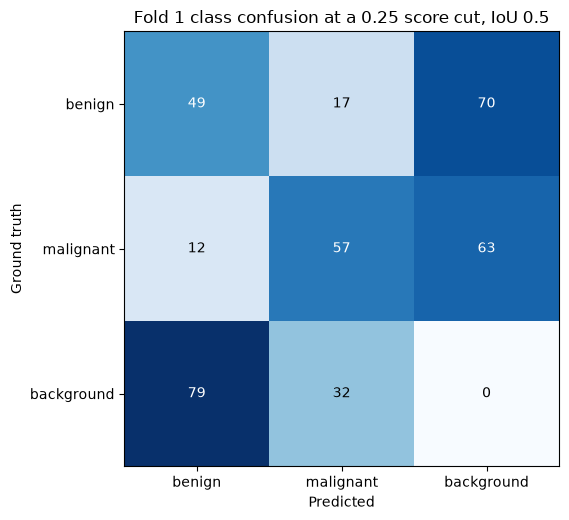

Fold 1
True positives  : 106
False negatives : 133
False positives : 111
Misclassified   : 29


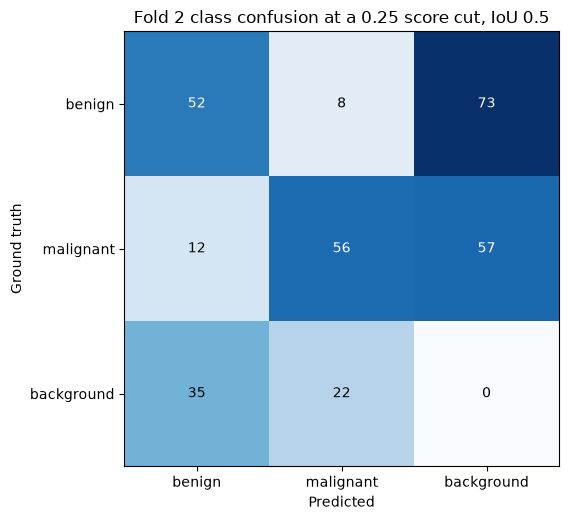

Fold 2
True positives  : 108
False negatives : 130
False positives : 57
Misclassified   : 20


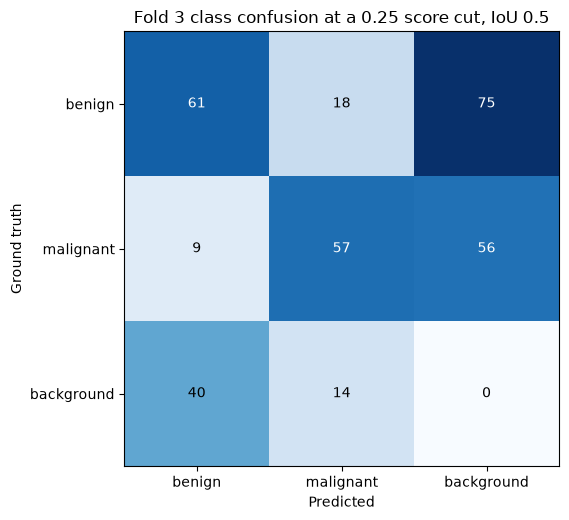

Fold 3
True positives  : 118
False negatives : 131
False positives : 54
Misclassified   : 27


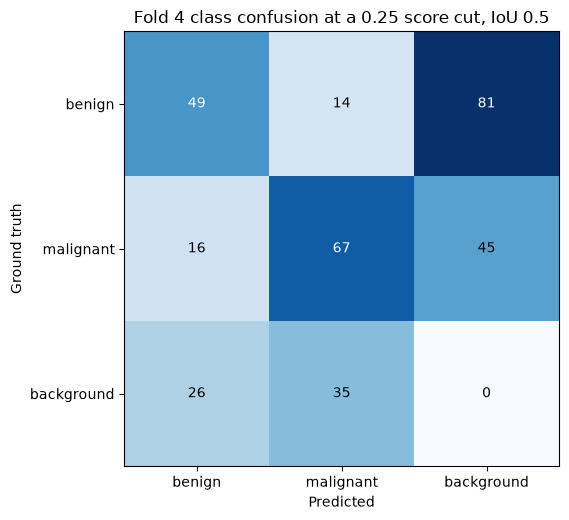

Fold 4
True positives  : 116
False negatives : 126
False positives : 61
Misclassified   : 30


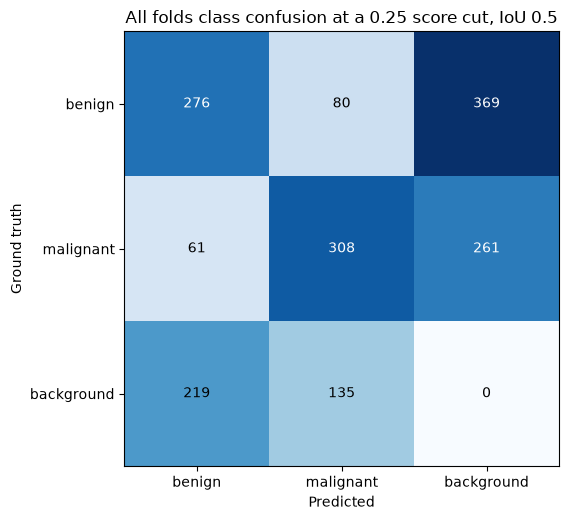

All folds
True positives  : 584
False negatives : 630
False positives : 354
Misclassified   : 141


In [12]:
# Block 12
# Class confusion per fold, plus the pooled matrix
classes = list(config.CLASS_NAMES)

fold_confusions = {
    fold: utility.detection_confusion(records, iou_threshold=config.YOLO_IOU_THRESHOLD, class_names=config.CLASS_NAMES)
    for fold, records in fold_predictions.items()
}

confusions = {f"fold {fold}": frame for fold, frame in fold_confusions.items()}

# Pooling the per-fold matrices is the same as one confusion over every fold's records
confusions["all folds"] = sum(fold_confusions.values())

for name, confusion in confusions.items():
    utility.plot_confusion(
        confusion,
        title=(
            f"{name.capitalize()} class confusion at a {config.YOLO_INFERENCE_SCORE_THRESHOLD} score cut, "
            f"IoU {config.YOLO_IOU_THRESHOLD}"
        ),
    )

    true_positive = int(np.trace(confusion.loc[classes, classes].to_numpy()))
    false_negative = int(confusion.loc[classes, "background"].sum())
    false_positive = int(confusion.loc["background", classes].sum())
    misclassified = int(confusion.loc[classes, classes].to_numpy().sum() - true_positive)

    print(f"{name.capitalize()}")
    print(f"True positives  : {true_positive:,}")
    print(f"False negatives : {false_negative:,}")
    print(f"False positives : {false_positive:,}")
    print(f"Misclassified   : {misclassified:,}")

In [13]:
# Block 13
# The five held-out fold checkpoints above, against the single model retrained on all trainval
import final_retrain

fold_checkpoints = sorted(config.MODELS_ROOT.glob(f"{LESION_TYPE}_yolo_fold*.pt"))
full_model = final_retrain.load_or_train("yolo")

print(f"Fold ensemble: {len(fold_checkpoints)} checkpoints, {config.MODELS_ROOT}")
print(f"Full retrain : {full_model.name}, {full_model.stat().st_size / 1e6:.1f} MB")

yolo: mass_yolo_full.pt is already on disk, not retraining
Fold ensemble: 5 checkpoints, C:\Users\User\Desktop\sch work\fyp\models
Full retrain : mass_yolo_full.pt, 20.3 MB


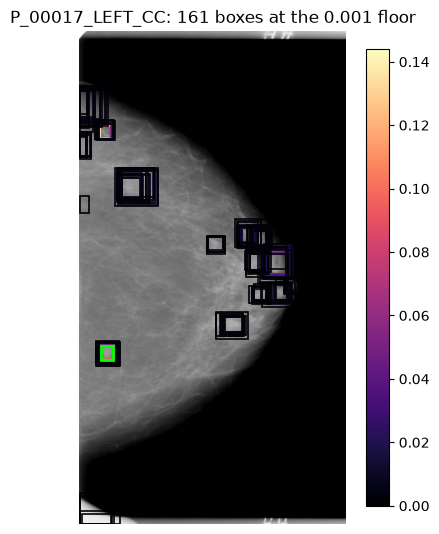

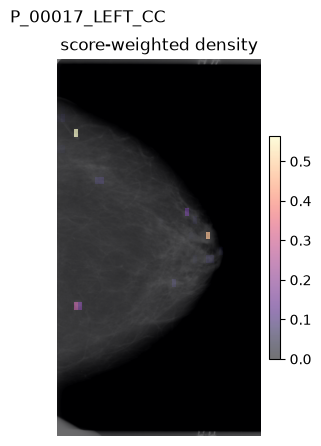

predict:   0%|          | 0/1 [00:00<?, ?it/s]

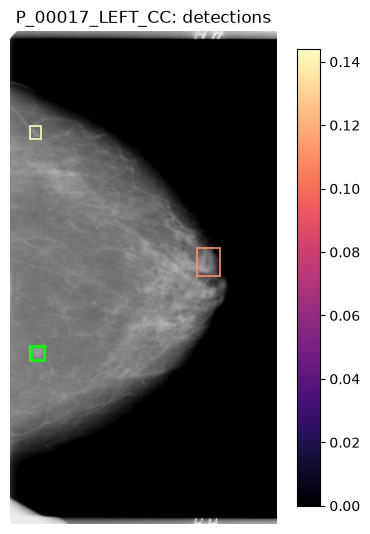

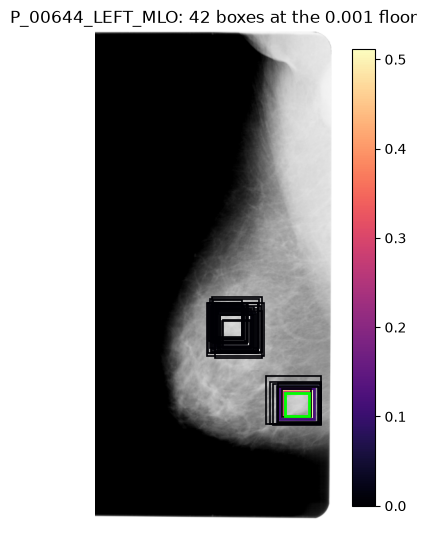

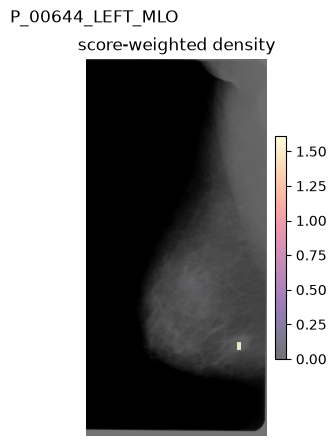

predict:   0%|          | 0/1 [00:00<?, ?it/s]

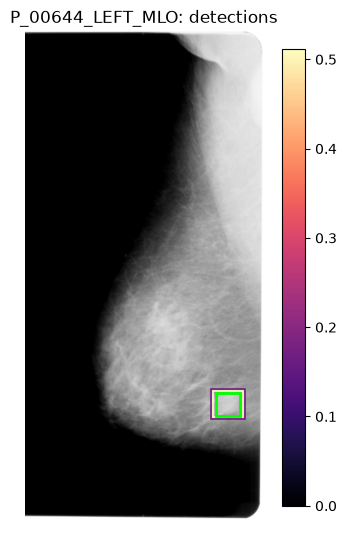

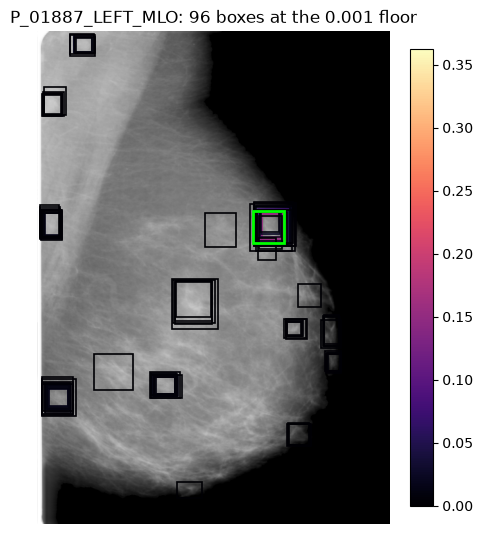

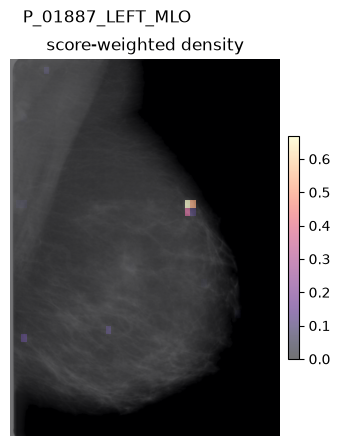

predict:   0%|          | 0/1 [00:00<?, ?it/s]

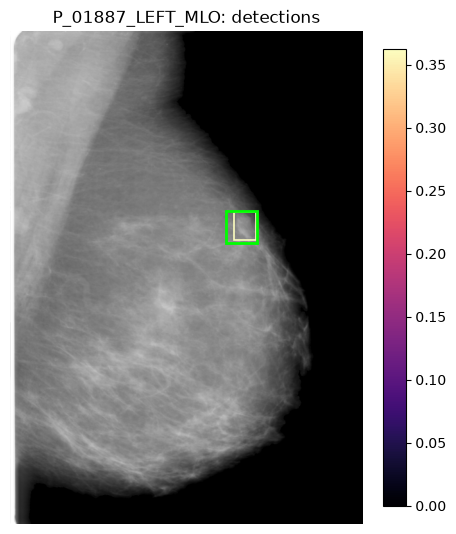

In [ ]:
# Block 14
# What YOLO sees on held-out mammograms: every box it fires on at a floor low enough to show the
# whole prediction field, then the boxes that survive at the operating threshold
scorer = YOLODetector(lesion_type=LESION_TYPE, device=device)
scorer.load(config.fold_model_path("yolo", LESION_TYPE, config.VAL_FOLD))

val_fold_df = trainval_df[trainval_df["fold"] == config.VAL_FOLD].reset_index(drop=True)

for index in np.linspace(0, len(val_fold_df) - 1, 3, dtype=int):
    row = val_fold_df.iloc[index]
    name = utility.mammogram_id(row.full_image)

    image, gt_boxes, _, boxes, scores = scorer.evidence(row)

    utility.plot_boxes_by_score(image, boxes, scores, gt_boxes, f"{name}: {len(boxes)} boxes at the 0.001 floor")
    utility.plot_heatmaps(
        image, [(utility.box_density_map(image.shape, boxes, scores), "score-weighted density")], name
    )

    entry = scorer.predict_raw(val_fold_df.iloc[[index]], score_threshold=config.YOLO_SCORE_THRESHOLD)[0]
    utility.plot_boxes_by_score(image, entry["boxes"], entry["scores"], gt_boxes, f"{name}: detections")